# 2015 — Residual Networks (ResNet)

**Paper:** Kaiming He, Xiangyu Zhang, Shaoqing Ren & Jian Sun, *"Deep Residual Learning for Image Recognition"* (2015). Won ImageNet 2015 with a 152-layer network.

**The degradation problem:** a deeper "plain" network had *higher training error* than a shallower one. This is not overfitting; the deeper net is simply harder to optimise, even though it could in principle copy the shallow one and use identity layers for the rest.

**The fix:** let each block learn a *residual* and add a shortcut:
$$y = x + \mathcal F(x)$$
Identity is now the default (just set $\mathcal F = 0$), and gradients flow straight through the shortcuts: $\partial y/\partial x = I + \partial\mathcal F/\partial x$. Residual connections are in almost every modern architecture, including every Transformer.

![Diagram: ResNet basic block (He et al., 2015)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/29_2015_resnet.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

def load_digits_tensors(size=8, test_size=0.2, seed=0):
    """sklearn's bundled 8x8 handwritten digits (1,797 images, no download needed).
    Returns X_train, y_train, X_test, y_test with X shaped (N, 1, size, size) in [0, 1]."""
    d = load_digits()
    X = torch.tensor(d.images, dtype=torch.float32).unsqueeze(1) / 16.0
    if size != 8:
        X = F.interpolate(X, size=(size, size), mode="bilinear", align_corners=False)
    y = torch.tensor(d.target, dtype=torch.long)
    tr, te = train_test_split(np.arange(len(y)), test_size=test_size, random_state=seed, stratify=d.target)
    return X[tr], y[tr], X[te], y[te]
Xtr, ytr, Xte, yte = [t.to(device) for t in load_digits_tensors(size=16)]

In [3]:
class Block(nn.Module):
    def __init__(self, c, residual):
        super().__init__()
        self.conv1, self.bn1 = nn.Conv2d(c, c, 3, padding=1, bias=False), nn.BatchNorm2d(c)
        self.conv2, self.bn2 = nn.Conv2d(c, c, 3, padding=1, bias=False), nn.BatchNorm2d(c)
        self.residual = residual
    def forward(self, x):
        out = self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x)))))
        return F.relu(out + x if self.residual else out)          # <- the only difference

class Net(nn.Module):
    def __init__(self, n_blocks, residual, c=16):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(1, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU())
        self.blocks = nn.Sequential(*[Block(c, residual) for _ in range(n_blocks)])
        self.head = nn.Linear(c, 10)
    def forward(self, x):
        return self.head(self.blocks(self.stem(x)).mean((2, 3)))

def train(n_blocks, residual, epochs=12):
    seed_everything(0)
    m = Net(n_blocks, residual).to(device)
    opt = torch.optim.SGD(m.parameters(), lr=0.05, momentum=0.9, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, 0.05, total_steps=epochs * ((len(Xtr) + 63) // 64))
    losses = []
    for ep in range(epochs):
        m.train(); perm = torch.randperm(len(Xtr), device=device); tot = 0
        for i in range(0, len(Xtr), 64):
            idx = perm[i:i + 64]
            loss = F.cross_entropy(m(Xtr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step(); sched.step(); tot += loss.item() * len(idx)
        losses.append(tot / len(Xtr))
    m.eval()
    with torch.no_grad(): acc = (m(Xte).argmax(1) == yte).float().mean().item()
    return losses, acc

## Plain vs. residual at increasing depth
Depth = 2 × blocks + 2 layers. Watch the **training** loss: plain networks get *worse* as they get deeper, while residual networks do not.

In [4]:
results = {}
for n_blocks in [2, 8, 20]:
    for residual in [False, True]:
        results[(n_blocks, residual)] = train(n_blocks, residual)
        l, acc = results[(n_blocks, residual)]
        print(f"{2 * n_blocks + 2:3d} layers  {'ResNet' if residual else 'plain ':6s}  final train loss {l[-1]:.4f}  test acc {acc:.3f}")

  6 layers  plain   final train loss 0.0737  test acc 0.986


  6 layers  ResNet  final train loss 0.0721  test acc 0.986


 18 layers  plain   final train loss 0.0519  test acc 0.978


 18 layers  ResNet  final train loss 0.0083  test acc 0.997


 42 layers  plain   final train loss 0.7043  test acc 0.783


 42 layers  ResNet  final train loss 0.0105  test acc 0.992


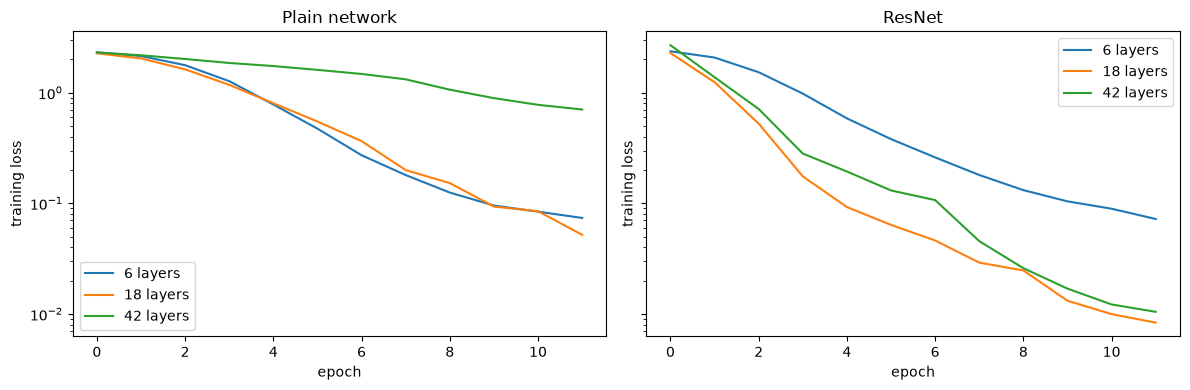

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, residual in zip(axes, [False, True]):
    for n_blocks in [2, 8, 20]:
        ax.plot(results[(n_blocks, residual)][0], label=f"{2 * n_blocks + 2} layers")
    ax.set(yscale="log", title="ResNet" if residual else "Plain network", xlabel="epoch", ylabel="training loss"); ax.legend()
plt.tight_layout(); plt.show()

## Gradient norm reaching the first layer

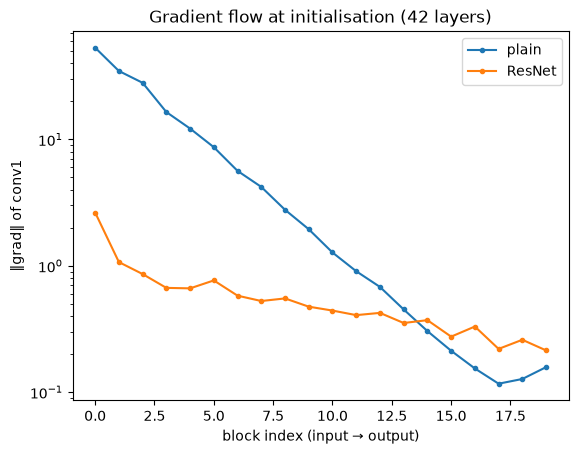

In [6]:
for residual in [False, True]:
    seed_everything(0); m = Net(20, residual).to(device)
    F.cross_entropy(m(Xtr[:128]), ytr[:128]).backward()
    g = [b.conv1.weight.grad.norm().item() for b in m.blocks]
    plt.semilogy(g, marker=".", label="ResNet" if residual else "plain")
plt.xlabel("block index (input → output)"); plt.ylabel("‖grad‖ of conv1"); plt.legend(); plt.title("Gradient flow at initialisation (42 layers)"); plt.show()